In [30]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

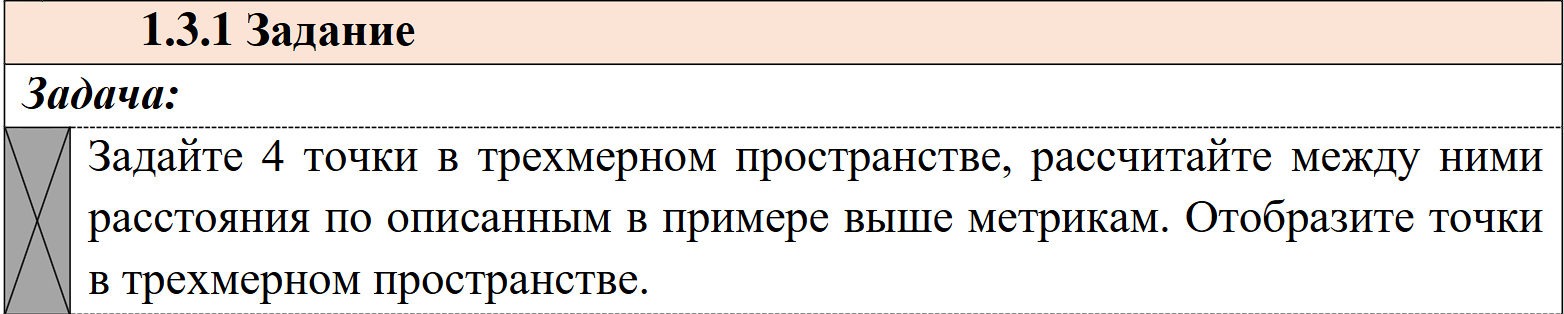

In [31]:
def euc_dist(p1, p2):
  return np.linalg.norm(p1 - p2)

def euc_dist_2(p1, p2):
  return np.linalg.norm(p1 - p2) ** 2

def weigth_euc_dist(p1, p2, w):
    return sum((x - y) ** 2 * w for x, y, w in zip(p1, p2, w)) ** 0.5

def cheb_dist(p1, p2):
  return max(abs(x - y) for x, y in zip(p1, p2))

def manh_dist(p1, p2):
  return sum(abs(x - y) for x, y in zip(p1, p2))


For [1 2 3] and [4 5 6]
5.196152422706632
27.0
7.3484692283495345
3
9

For [1 2 3] and [7 8 9]
10.392304845413264
108.0
14.696938456699069
6
18

For [1 2 3] and [10 11 12]
15.588457268119896
243.0
22.045407685048602
9
27

For [4 5 6] and [7 8 9]
5.196152422706632
27.0
7.3484692283495345
3
9

For [4 5 6] and [10 11 12]
10.392304845413264
108.0
14.696938456699069
6
18

For [7 8 9] and [10 11 12]
5.196152422706632
27.0
7.3484692283495345
3
9



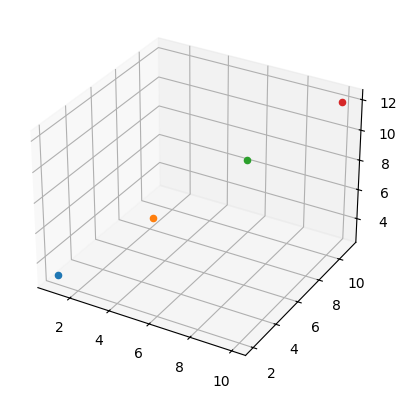

In [32]:
p1 = np.array([1, 2, 3])
p2 = np.array([4, 5, 6])
p3 = np.array([7, 8, 9])
p4 = np.array([10, 11, 12])
done = set()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
for x in [p1, p2, p3, p4]:
  ax.scatter(x[0], x[1], x[2])


for i in [p1, p2, p3, p4]:
  for j in [p1, p2, p3, p4]:

    if i is j:
      continue

    current_pair = frozenset({tuple(i), tuple(j)})

    if current_pair in done:
      continue

    done.add(current_pair)
    print(f'For {i} and {j}')
    print(euc_dist(i, j))
    print(euc_dist_2(i, j))
    print(weigth_euc_dist(i, j, [1, 2, 3]))
    print(cheb_dist(i, j))
    print(manh_dist(i, j))
    print()


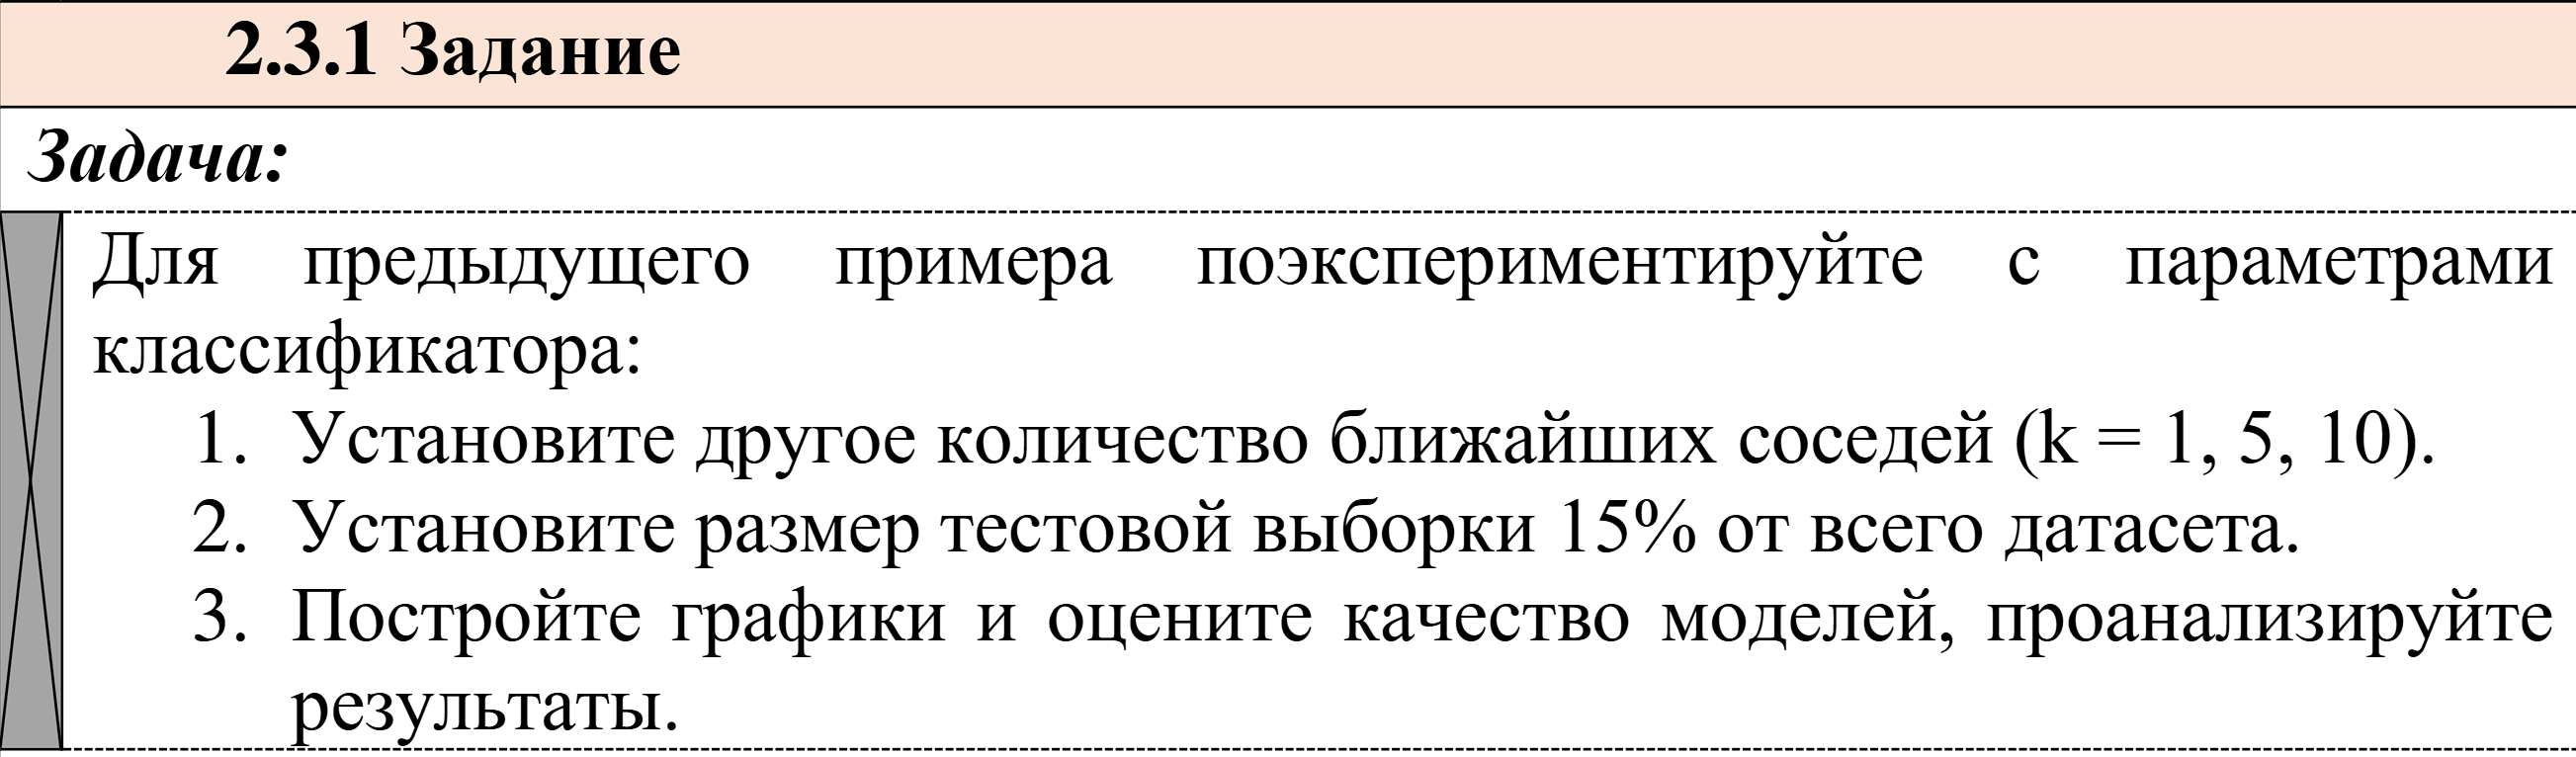

In [33]:
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
from sklearn.model_selection import train_test_split

iris = sns.load_dataset('iris')

In [34]:
x_train, x_test, y_train, y_test = train_test_split(iris.iloc[:, :-1], iris.iloc[:, -1], test_size=0.15)

model = KNeighborsClassifier(n_neighbors=1)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

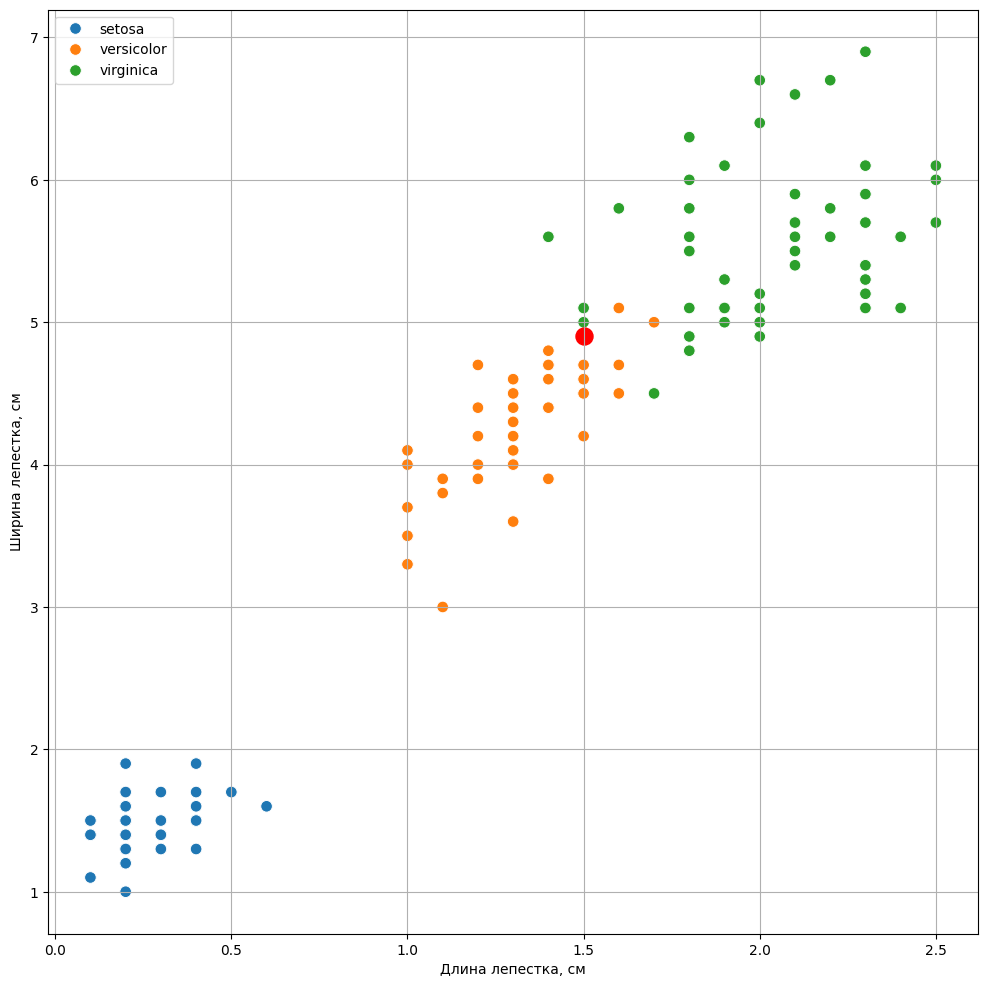

In [35]:
plt.figure(figsize=(12, 12))
sns.scatterplot(x='petal_width', y='petal_length', data=iris, hue='species', s = 70)
plt.xlabel('Длина лепестка, см')
plt.ylabel('Ширина лепестка, см')
plt.legend(loc=2)
plt.grid()

for i in range(len(y_test)):
  if np.array(y_test) [i] != y_pred[i]:
    plt.scatter(x_test.iloc[i, 3], x_test.iloc[i, 2], color='red', s = 150 )

In [36]:
from sklearn.metrics import accuracy_score
print(f'Accutacy : {accuracy_score(y_test, y_pred) :.4}')

Accutacy : 0.9565


In [37]:
x_train, x_test, y_train, y_test = train_test_split(iris.iloc[:, :-1], iris.iloc[:, -1], test_size=0.15)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

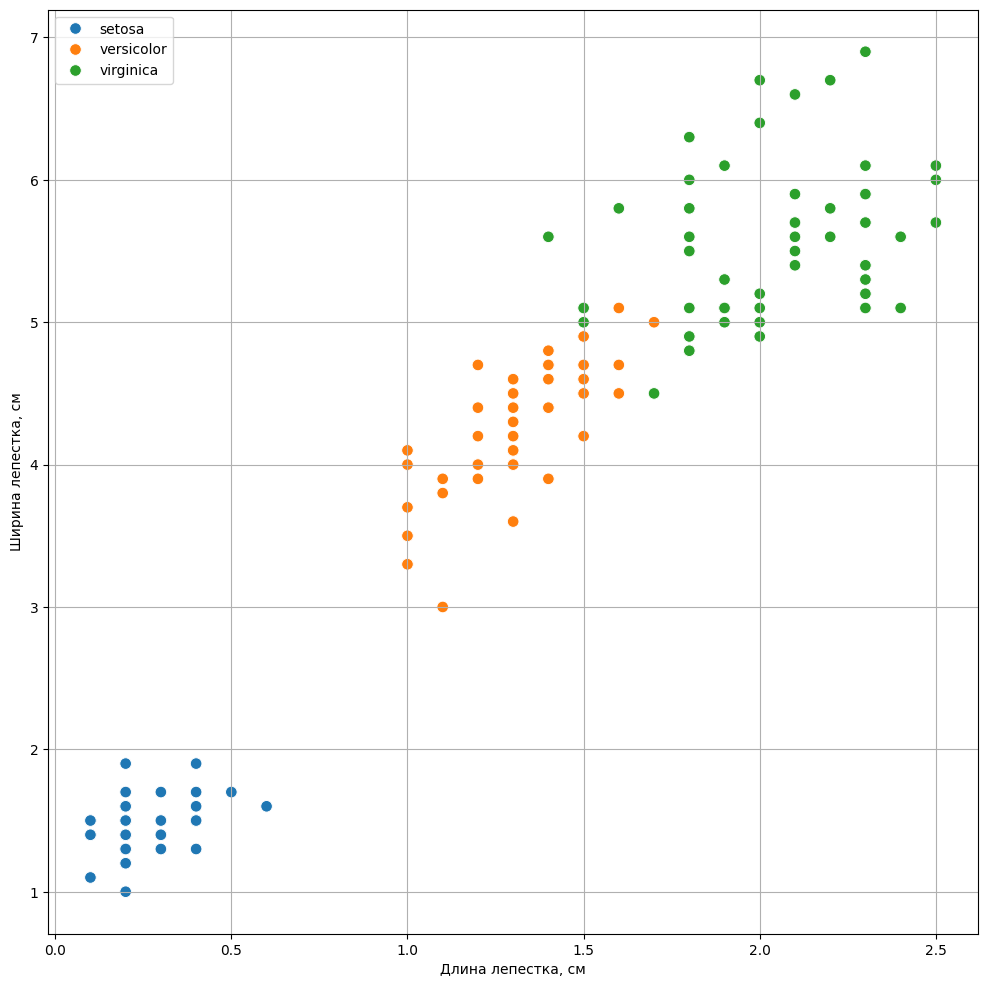

In [38]:
plt.figure(figsize=(12, 12))
sns.scatterplot(x='petal_width', y='petal_length', data=iris, hue='species', s = 70)
plt.xlabel('Длина лепестка, см')
plt.ylabel('Ширина лепестка, см')
plt.legend(loc=2)
plt.grid()

for i in range(len(y_test)):
  if np.array(y_test) [i] != y_pred[i]:
    plt.scatter(x_test.iloc[i, 3], x_test.iloc[i, 2], color='red', s = 150 )

In [39]:
x_train, x_test, y_train, y_test = train_test_split(iris.iloc[:, :-1], iris.iloc[:, -1], test_size=0.15)

model = KNeighborsClassifier(n_neighbors=10)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

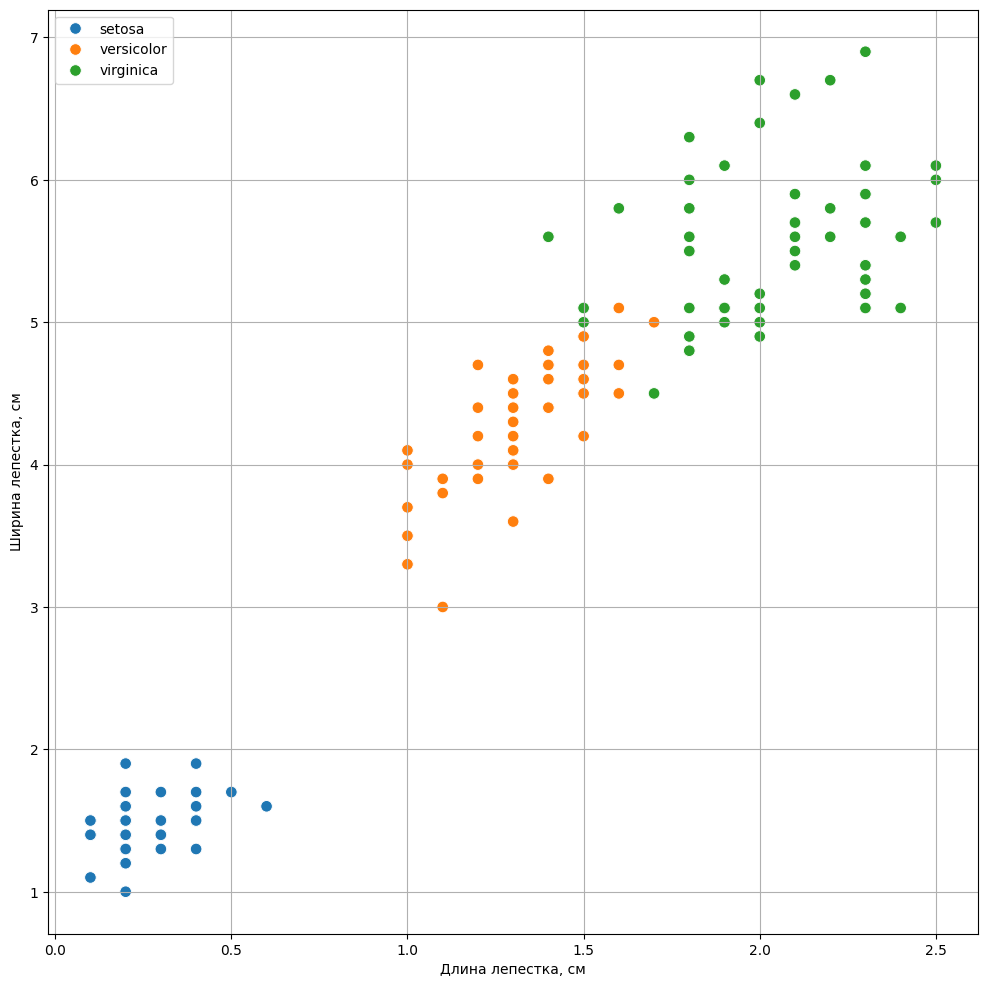

In [40]:
plt.figure(figsize=(12, 12))
sns.scatterplot(x='petal_width', y='petal_length', data=iris, hue='species', s = 70)
plt.xlabel('Длина лепестка, см')
plt.ylabel('Ширина лепестка, см')
plt.legend(loc=2)
plt.grid()

for i in range(len(y_test)):
  if np.array(y_test) [i] != y_pred[i]:
    plt.scatter(x_test.iloc[i, 3], x_test.iloc[i, 2], color='red', s = 150 )

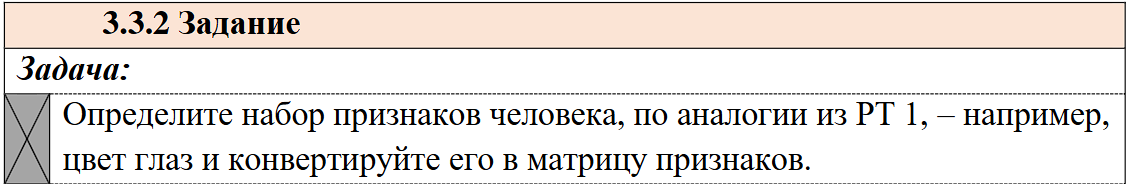

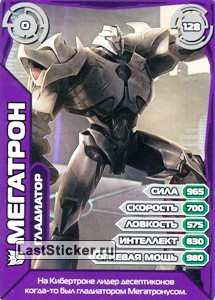

In [41]:
from sklearn.feature_extraction import DictVectorizer

In [42]:
data = [
    {"сила": 85, "скорость": 42, "ловкость": 71, "интеллект": 93, "огневая мощь": 15},
    {"сила": 12, "скорость": 99, "ловкость": 53, "интеллект": 64, "огневая мощь": 88},
    {"сила": 50, "скорость": 15, "ловкость": 82, "интеллект": 45, "огневая мощь": 76},
    {"сила": 93, "скорость": 67, "ловкость": 29, "интеллект": 81, "огневая мощь": 54}
]

vectorizer = DictVectorizer(sparse=False)

features = vectorizer.fit_transform(data)
print(features)


[[93. 71. 15. 85. 42.]
 [64. 53. 88. 12. 99.]
 [45. 82. 76. 50. 15.]
 [81. 29. 54. 93. 67.]]
